# Лабораторна робота №2

**Виконав: Рацюк Ілля група 4-9**  

---

## Завдання 1. Завантажити датасет і показати перші п’ять рядків



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from io import StringIO

link = 'https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)'

response = requests.get(link, headers={'User-Agent': 'Mozilla/5.0'}, timeout=30)
response.raise_for_status()

all_tables = pd.read_html(StringIO(response.text))
candidates = [t for t in all_tables if all(word in str(t.columns) for word in ('IMF', 'World Bank', 'United Nations'))]

if not candidates:
    raise RuntimeError('Не вдалося знайти таблицю ВВП на сторінці')

df = candidates[0].copy()

print('Перші п’ять записів:')
print(df.head().to_string(index=False))


Перші п’ять записів:
Country/Territory IMF (2026)[1] World Bank (2025)[6] United Nations (2024)[7]
            World     126295331            118350166                111565144
    United States      32383920             30769700                 29298000
       China[n 1]      20851593             19498039                 18743802
          Germany       5452858              5050923                  4659929
            Japan       4379253              4435163                  4026211


---

## Завдання 2. Розмір датасету



In [2]:
rows, cols = df.shape

print("Рядки:", rows)
print("Стовпці:", cols)


Рядки: 222
Стовпці: 4


---

## Завдання 3. Вибрати потрібні стовпці



In [3]:
new_names = ['Country', 'IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']
df = df.iloc[:, 0:4].set_axis(new_names, axis=1).copy()
df['Country'] = df['Country'].astype(str).str.replace(r'\[[^]]*\]', '', regex=True).str.strip()
df = df.query('Country != "World" and Country != "European Union"').reset_index(drop=True)
indicators = new_names[1:]

print(df.head(5).to_string(index=False))


       Country IMF (2026) World Bank (2025) United Nations (2024)
 United States   32383920          30769700              29298000
         China   20851593          19498039              18743802
       Germany    5452858           5050923               4659929
         Japan    4379253           4435163               4026211
United Kingdom    4264794           4002588               3685881


---

## Завдання 4. Замінити «—» на NaN, перевірити та заповнити пропуски



In [4]:
df.replace({'—': np.nan, '–': np.nan, '-': np.nan, '': np.nan}, inplace=True)

for key in indicators:
    series = df[key].astype(str).str.replace(r'[,\s]', '', regex=True)
    df[key] = pd.to_numeric(series, errors='coerce')

print('Відсутні значення:')

display(df[indicators].isnull().sum().to_frame('Кількість'))
original = df.copy()
means_before = df[indicators].mean()

df[indicators] = df[indicators].fillna(means_before)

print('Після заміни:', df[indicators].isna().sum().sum())


Відсутні значення:


,Кількість
IMF (2026),31
World Bank (2025),35
United Nations (2024),9


Після заміни: 0


---

## Завдання 5. Вивести очищений датасет



In [5]:
print(df.to_string(index=False))


                         Country   IMF (2026)  World Bank (2025)  United Nations (2024)
                   United States 3.238392e+07       3.076970e+07           2.929800e+07
                           China 2.085159e+07       1.949804e+07           1.874380e+07
                         Germany 5.452858e+06       5.050923e+06           4.659929e+06
                           Japan 4.379253e+06       4.435163e+06           4.026211e+06
                  United Kingdom 4.264794e+06       4.002588e+06           3.685881e+06
                           India 4.153191e+06       3.956067e+06           3.952244e+06
                          France 3.596094e+06       3.366316e+06           3.160443e+06
                           Italy 2.738164e+06       2.551557e+06           2.380825e+06
                          Russia 2.656452e+06       2.561310e+06           2.173386e+06
                          Brazil 2.635912e+06       2.279920e+06           2.185822e+06
                          Canada

---

## Завдання 6. Перевірити і прибрати дублікати



In [6]:
duplicates = df.duplicated(keep='first')

print('Повторюваних рядків:', duplicates.sum())

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
original = original.drop_duplicates().reset_index(drop=True)

print('Залишилося рядків:', len(df))


Повторюваних рядків: 0
Залишилося рядків: 221


---

## Завдання 7. Описова статистика



In [7]:
statistics = df[indicators].describe()

print(statistics.round(1).to_string())


       IMF (2026)  World Bank (2025)  United Nations (2024)
count       221.0              221.0                  221.0
mean     661460.3           626049.7               522491.2
std     2666759.2          2520399.4              2410079.3
min          65.0               57.0                   56.0
25%       18959.0            19928.0                 8840.0
50%      102042.0            99774.0                42765.0
75%      661460.3           626049.7               298697.0
max    32383920.0         30769700.0             29298000.0


---

## Завдання 8. Різниця між IMF (2026) і World Bank (2025)



In [8]:
valid = original.dropna(subset=indicators).copy()
valid = valid.assign(gap=valid['IMF (2026)'].sub(valid['World Bank (2025)']))
valid['absolute_gap'] = valid['gap'].abs()
report = valid.sort_values('absolute_gap', ascending=False).head(10)

print(report[['Country', 'gap', 'absolute_gap']].to_string(index=False))
print('Висновок: найбільше розходження у країни', report.iloc[0]['Country'])


       Country       gap  absolute_gap
 United States 1614220.0     1614220.0
         China 1353554.0     1353554.0
       Germany  401935.0      401935.0
        Brazil  355992.0      355992.0
     Australia  325444.0      325444.0
        Mexico  288214.0      288214.0
United Kingdom  262206.0      262206.0
        France  229778.0      229778.0
         India  197124.0      197124.0
        Canada  187440.0      187440.0
Висновок: найбільше розходження у країни United States


---

## Завдання 9. Кореляція між трьома показниками



                       IMF (2026)  World Bank (2025)  United Nations (2024)
IMF (2026)                 1.0000             0.9999                 0.9998
World Bank (2025)          0.9999             1.0000                 0.9999
United Nations (2024)      0.9998             0.9999                 1.0000


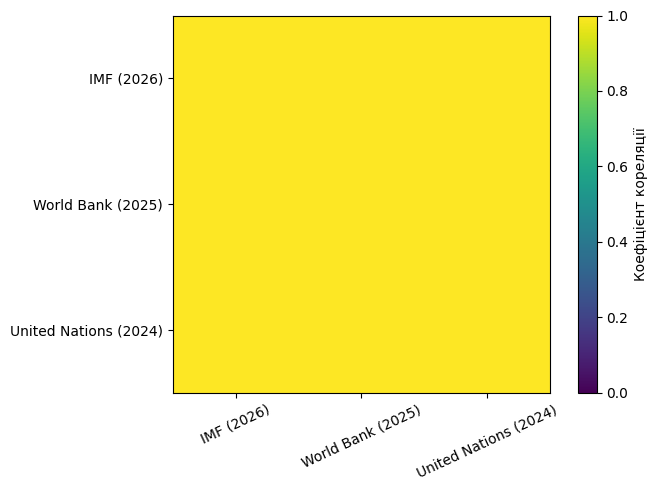

Найсильніший зв’язок: ('IMF (2026)', 'World Bank (2025)', np.float64(0.9998791099756853))


In [9]:
correlation = valid[indicators].corr(method='pearson')

print(correlation.round(4).to_string())

plt.figure(figsize=(7, 5))
plt.imshow(correlation, vmin=0, vmax=1, cmap='viridis')
plt.xticks(range(3), indicators, rotation=25)
plt.yticks(range(3), indicators)
plt.colorbar(label='Коефіцієнт кореляції')
plt.tight_layout()
plt.show()
pairs = [(indicators[i], indicators[j], correlation.iloc[i, j]) for i in range(3) for j in range(i+1,3)]

print('Найсильніший зв’язок:', max(pairs, key=lambda pair: pair[2]))


---

## Завдання 10. Середні значення за стовпцями



IMF (2026): 661,460.29 млн дол.
World Bank (2025): 626,049.69 млн дол.
United Nations (2024): 522,491.21 млн дол.


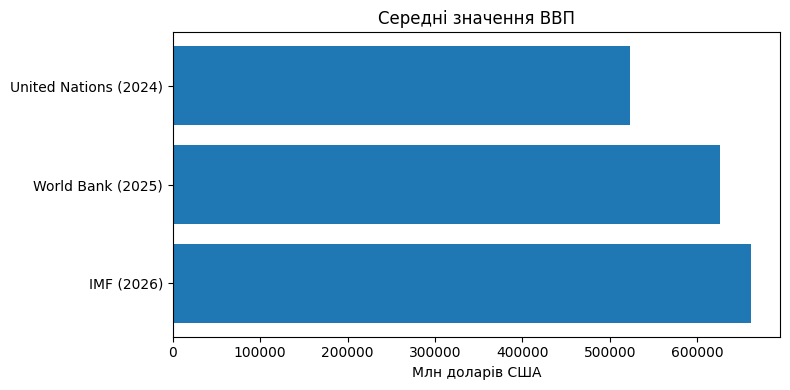

In [10]:
means = df[indicators].agg('mean')

for key, value in means.items():
    print(f'{key}: {value:,.2f} млн дол.')

plt.figure(figsize=(8,4))
plt.barh(means.index, means.values)
plt.title('Середні значення ВВП')
plt.xlabel('Млн доларів США')
plt.tight_layout()
plt.show()


---

## Завдання 11. Стандартне відхилення по країнах



In [11]:
valid['std_gdp'] = valid[indicators].std(axis='columns')
ranking = valid.sort_values('std_gdp', ascending=False)[['Country','std_gdp']]

print(ranking.head(10).to_string(index=False))
print('Перша країна у списку має найбільшу варіативність:', ranking.iloc[0, 0])


       Country      std_gdp
 United States 1.543508e+06
         China 1.068002e+06
       Germany 3.964771e+05
United Kingdom 2.898838e+05
        Russia 2.558938e+05
        Brazil 2.374046e+05
         Japan 2.217380e+05
        France 2.179348e+05
         Spain 1.842383e+05
     Australia 1.793505e+05
Перша країна у списку має найбільшу варіативність: United States


---

## Завдання 12. Максимум та мінімум кожного показника



In [12]:
for metric in indicators:
    present = original[['Country', metric]].dropna()
    maximum = present.nlargest(1, metric).iloc[0]
    minimum = present.nsmallest(1, metric).iloc[0]
    print('\n', metric)
    print('Найбільше:', maximum.Country, maximum[metric])
    print('Найменше:', minimum.Country, minimum[metric])



 IMF (2026)
Найбільше: United States 32383920.0
Найменше: Tuvalu 65.0

 World Bank (2025)
Найбільше: United States 30769700.0
Найменше: Tuvalu 57.0

 United Nations (2024)
Найбільше: United States 29298000.0
Найменше: Tuvalu 56.0


---

## Завдання 13. Гістограма IMF (2026) та особливості розподілу



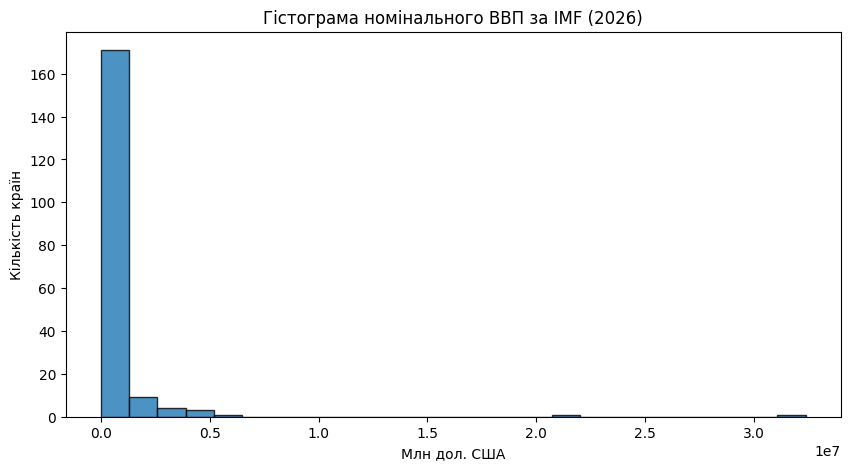

       Country  IMF (2026)
 United States  32383920.0
         China  20851593.0
       Germany   5452858.0
         Japan   4379253.0
United Kingdom   4264794.0
Більшість спостережень зосереджена біля малих значень; декілька країн утворюють довгий правий хвіст.


In [13]:
values = original['IMF (2026)'].dropna()
fig, ax = plt.subplots(figsize=(10,5))
ax.hist(values, bins=25, edgecolor='black', alpha=.8)
ax.set(title='Гістограма номінального ВВП за IMF (2026)', xlabel='Млн дол. США', ylabel='Кількість країн')
plt.show()

print(original[['Country','IMF (2026)']].sort_values('IMF (2026)', ascending=False).head(5).to_string(index=False))
print('Більшість спостережень зосереджена біля малих значень; декілька країн утворюють довгий правий хвіст.')


---

## Завдання 14. Частка кожної країни в сукупному ВВП



       Country  IMF (2026)  World Bank (2025)  United Nations (2024)  зміна_частки
 United States      25.767             26.424                 26.450        -0.682
         China      16.591             16.744                 16.922        -0.330
       Germany       4.339              4.338                  4.207         0.132
         Japan       3.485              3.809                  3.635        -0.150
United Kingdom       3.393              3.437                  3.328         0.066
         India       3.305              3.397                  3.568        -0.263
        France       2.861              2.891                  2.853         0.008
         Italy       2.179              2.191                  2.149         0.029
        Russia       2.114              2.200                  1.962         0.152
        Brazil       2.097              1.958                  1.973         0.124
        Canada       1.995              1.992                  2.049        -0.054
    

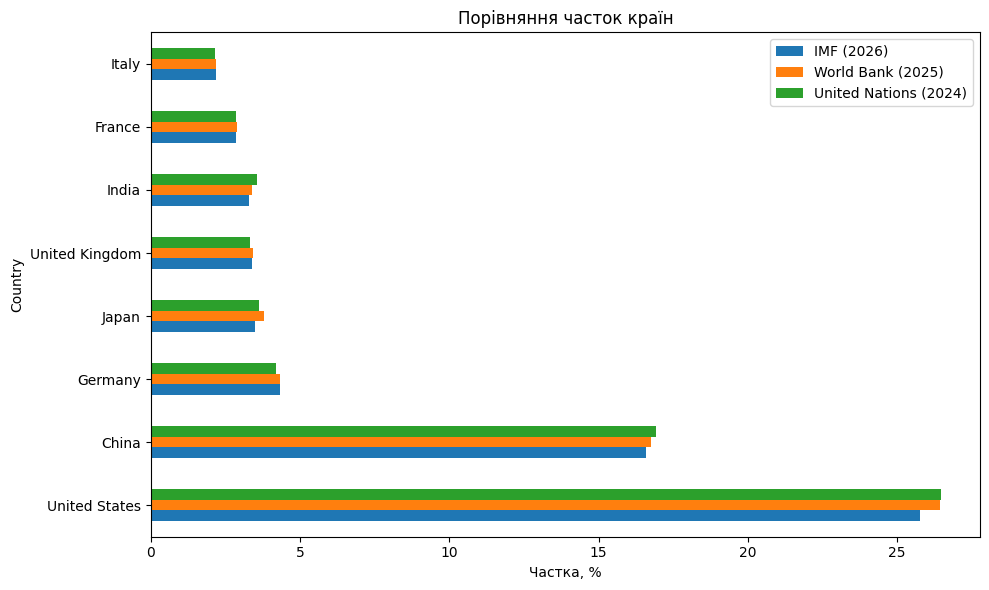

In [14]:
percent = original[['Country']].copy()
percent[indicators] = original[indicators].div(original[indicators].sum()).mul(100)
percent['зміна_частки'] = percent['IMF (2026)'] - percent['United Nations (2024)']

print(percent.head(15).round(3).to_string(index=False))
print('\nЗбільшили частку найсильніше:')
print(percent.nlargest(5, 'зміна_частки')[['Country','зміна_частки']].to_string(index=False))
print('\nЗменшили частку найсильніше:')
print(percent.nsmallest(5, 'зміна_частки')[['Country','зміна_частки']].to_string(index=False))

large_names = original.nlargest(8,'IMF (2026)')['Country']
percent.set_index('Country').loc[large_names, indicators].plot(kind='barh', figsize=(10,6))
plt.xlabel('Частка, %')
plt.title('Порівняння часток країн')
plt.tight_layout()
plt.show()


---

## Завдання 15. Динаміка показників за 2024–2026 роки



In [15]:
import plotly.express as px

ordered = ['United Nations (2024)', 'World Bank (2025)', 'IMF (2026)']
complete = original.dropna(subset=ordered).copy()
reshaped = complete.melt(id_vars='Country', value_vars=ordered, var_name='Джерело', value_name='ВВП')
chart = px.line(reshaped, x='Джерело', y='ВВП', color='Country', markers=True, category_orders={'Джерело': ordered}, title='ВВП за 2024, 2025 і 2026 роки')
chart.update_layout(height=700)
chart.show()
growing = complete.loc[(complete[ordered[0]] < complete[ordered[1]]) & (complete[ordered[1]] < complete[ordered[2]]), 'Country']

shrinking = complete.loc[(complete[ordered[0]] > complete[ordered[1]]) & (complete[ordered[1]] > complete[ordered[2]]), 'Country']

print('Стабільне зростання:', len(growing), 'країн:')
print(growing.head(15).to_list())
print('Стабільний спад:', len(shrinking), 'країн:')
print(shrinking.head(15).to_list())


Стабільне зростання: 156 країн:
['United States', 'China', 'Germany', 'United Kingdom', 'India', 'France', 'Italy', 'Russia', 'Brazil', 'Canada', 'Spain', 'Turkey', 'Indonesia', 'Netherlands', 'Saudi Arabia']
Стабільний спад: 2 країн:
['Iran', 'Ethiopia']
